# 03 · Modeling & Evaluation
Compare candidate models with repeated stratified CV, tune the best, evaluate once on the held-out test set, and interpret the result.

*(The same logic is available as scripts: `python -m src.train` and `python -m src.evaluate`.)*

In [1]:
import sys; sys.path.append("..")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src.data_prep import *
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
import json, joblib
from pathlib import Path
REP = Path('..')/'reports'; FIGS = REP/'figures'
from IPython.display import Image, display

## 1. Baseline model comparison (train set only, 5-fold × 3 repeats)

In [2]:
comp = pd.read_csv(REP/'model_comparison.csv')
display(comp[['model','roc_auc_mean','roc_auc_std','recall_mean','precision_mean','f1_mean','accuracy_mean']].round(3))

,model,roc_auc_mean,roc_auc_std,recall_mean,precision_mean,f1_mean,accuracy_mean
0,Logistic Regression,0.892,0.043,0.762,0.848,0.798,0.824
1,Random Forest,0.888,0.042,0.753,0.788,0.765,0.791
2,KNN,0.879,0.041,0.792,0.818,0.801,0.821
3,SVM (RBF),0.878,0.045,0.759,0.829,0.788,0.814
4,XGBoost,0.862,0.039,0.762,0.762,0.757,0.778
5,Naive Bayes,0.859,0.057,0.882,0.656,0.744,0.717
6,Gradient Boosting,0.848,0.045,0.765,0.766,0.762,0.782


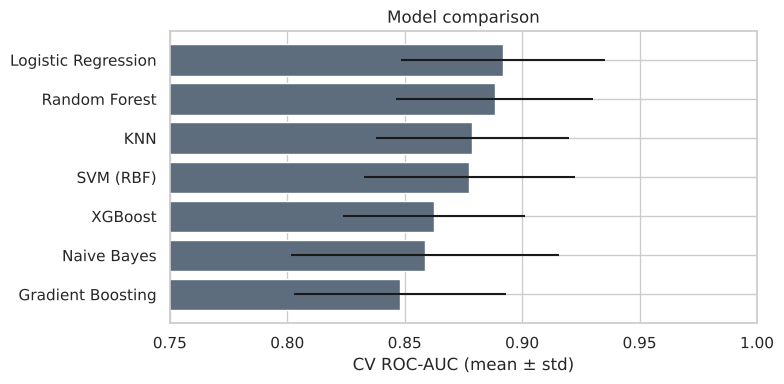

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
c = comp.sort_values('roc_auc_mean')
ax.barh(c['model'], c['roc_auc_mean'], xerr=c['roc_auc_std'], color='#5d6d7e')
ax.set_xlim(0.75, 1); ax.set_xlabel('CV ROC-AUC (mean ± std)'); ax.set_title('Model comparison'); plt.tight_layout(); plt.show()

All models land within about one standard deviation of each other: with ~240 training patients, differences between them are **not statistically meaningful**. Simple, interpretable models are competitive with boosting.

## 2. Hyper-parameter tuning

In [4]:
meta = json.loads((Path('..')/'models'/'model_meta.json').read_text())
print(json.dumps(meta, indent=2))

{
  "best_model": "Logistic Regression",
  "cv_auc": 0.8999,
  "best_params": {
    "clf__C": 0.1
  },
  "tuned_cv_auc": {
    "Logistic Regression": 0.8999,
    "SVM (RBF)": 0.8952,
    "Random Forest": 0.8922,
    "XGBoost": 0.8805
  },
  "random_state": 42
}


## 3. Held-out test performance

In [5]:
m = json.loads((REP/'metrics.json').read_text())
print(json.dumps(m, indent=2))

{
  "model": "Logistic Regression",
  "n_test": 61,
  "roc_auc": 0.961,
  "pr_auc": 0.949,
  "default_threshold": {
    "threshold": 0.5,
    "accuracy": 0.885,
    "precision": 0.839,
    "recall": 0.929,
    "specificity": 0.848,
    "f1": 0.881
  },
  "recall>=90%_threshold": {
    "threshold": 0.29,
    "accuracy": 0.82,
    "precision": 0.718,
    "recall": 1.0,
    "specificity": 0.667,
    "f1": 0.836
  },
  "roc_auc_95ci": [
    0.905,
    0.998
  ],
  "fairness_note": "See reports/fairness_by_group.csv (small subgroups; interpret with caution)"
}


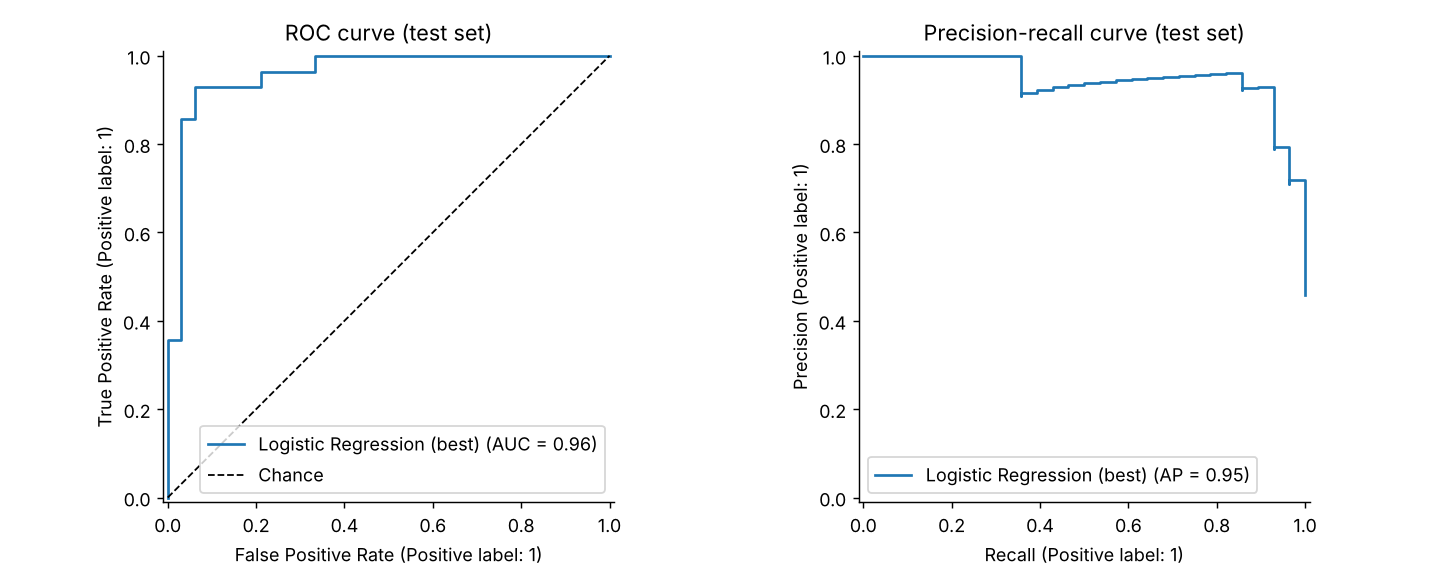

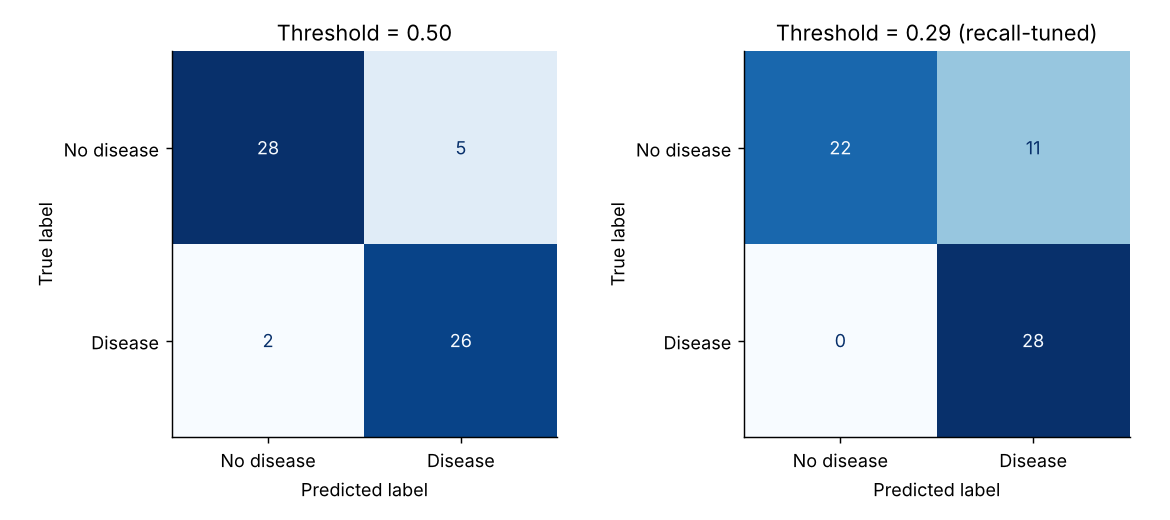

In [6]:
display(Image(FIGS/'roc_pr_curves.png'))
display(Image(FIGS/'confusion_matrices.png'))

**Threshold tuning.** In screening, missing a sick patient is worse than a false alarm. The threshold was chosen using *out-of-fold predictions on the training set* so that recall ≥ 90%, then applied to the test set. This trades specificity for sensitivity.

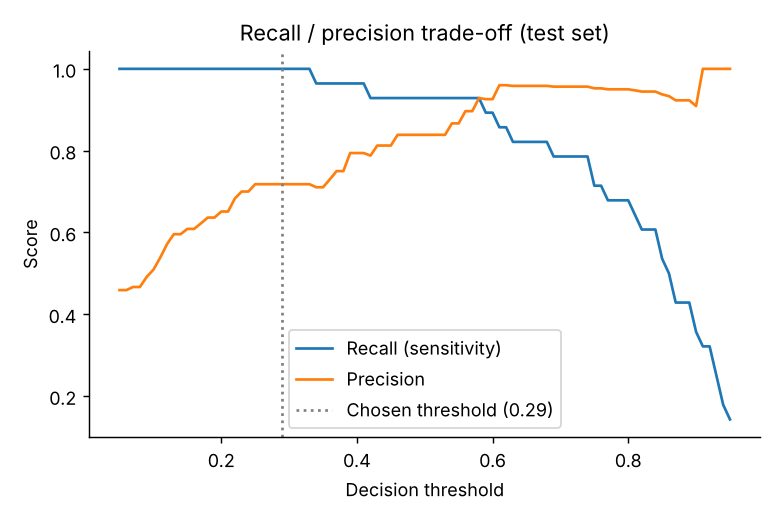

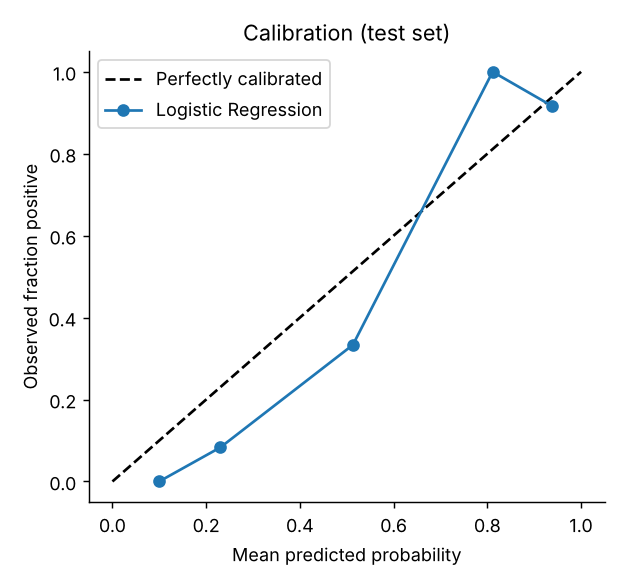

In [7]:
display(Image(FIGS/'threshold_tradeoff.png'))
display(Image(FIGS/'calibration.png'))

## 4. Interpretability

In [8]:
odds = pd.read_csv(REP/'odds_ratios.csv', index_col=0)
display(odds.head(8)); display(odds.tail(5))

,coef,odds_ratio
ca,0.700,2.014
cp_4.0,0.552,1.736
sex,0.535,1.708
thal_7.0,0.530,1.699
exang,0.378,1.460
slope_2.0,0.297,1.345
oldpeak,0.246,1.279
trestbps,0.170,1.185


,coef,odds_ratio
cp_1.0,-0.191,0.827
slope_1.0,-0.252,0.777
cp_3.0,-0.294,0.745
thalach,-0.327,0.721
thal_3.0,-0.515,0.598


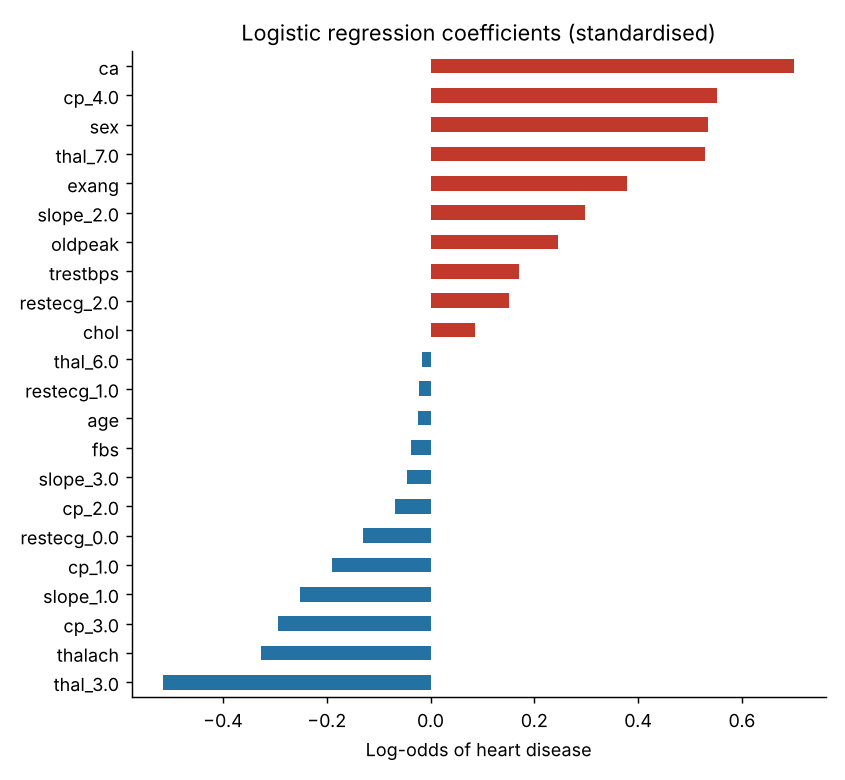

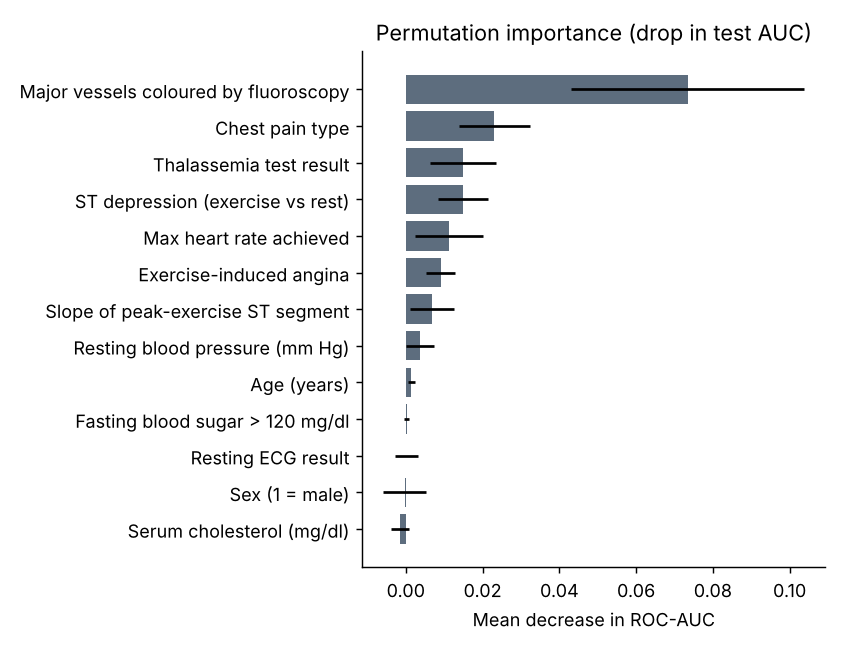

In [9]:
display(Image(FIGS/'coefficients.png'))
display(Image(FIGS/'permutation_importance.png'))

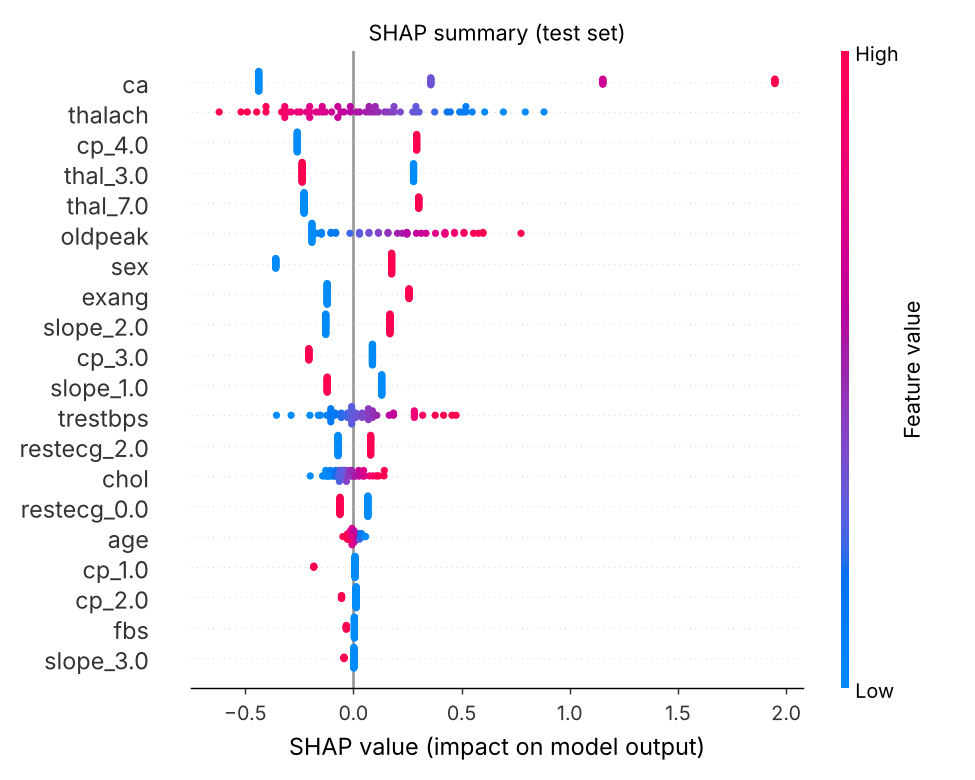

In [10]:
display(Image(FIGS/'shap_summary.png'))

## 5. Subgroup check

In [11]:
display(pd.read_csv(REP/'fairness_by_group.csv'))

,group,n,disease_rate,roc_auc,recall,precision
0,Sex: Female,20,0.35,1.000,1.0,0.778
1,Sex: Male,41,0.51,0.948,1.0,0.700
2,Age band: <55,28,0.25,1.000,1.0,0.583
3,Age band: 55-64,27,0.67,0.895,1.0,0.857
4,Age band: 65+,6,0.50,1.000,1.0,0.500


Subgroups contain only 6-41 patients, so these numbers are very noisy. They are a sanity check, not evidence of fairness.

## Conclusions
- A tuned **logistic regression** matches or beats tree ensembles here and is fully interpretable.
- Most influential factors: number of vessels with calcification (`ca`), asymptomatic chest pain, reversible-defect thal, male sex, exercise-induced angina, ST depression, lower max heart rate.
- The test AUC (n = 61) has a wide confidence interval; the cross-validated AUC (~0.90) is the more reliable estimate.
- **Not a clinical tool**: small, single-site, 1980s data.